# Day 2 - Decision Tree Regressor "classifier" (Optional)
Interestingly, you can use the [DecisionTreeRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html) to do classification tasks as well.

But instead of an integer of the specific class you would get a float as the predicted label.

You will use the dataset in *"diabetes.csv"*. It has several health-related columns and the outcome of a diabetes test.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn import metrics


### Build a classifier

#### 1. Read diabetes data.

In [2]:
diab = pd.read_csv("diabetes.csv")
print(diab.shape)
diab.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


#### 2. Explore and visualize data. Make conclusions.

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


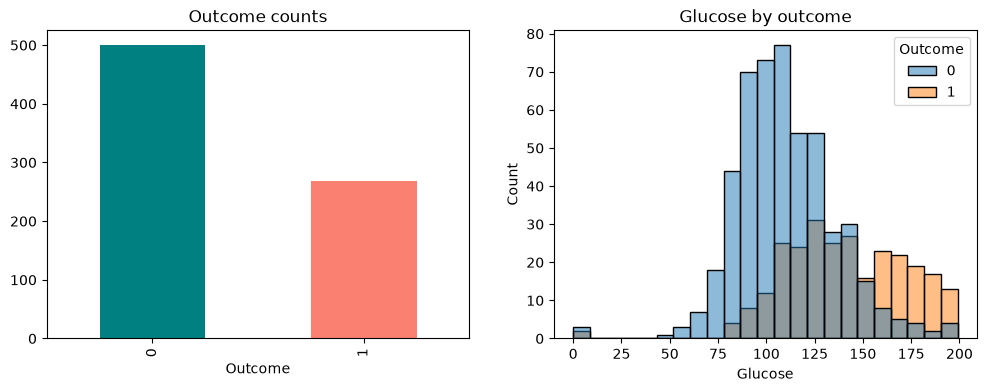

In [3]:
# zeros here are actually missing values
print((diab[["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]] == 0).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
diab["Outcome"].value_counts().plot(kind="bar", ax=ax[0], color=["teal", "salmon"])
ax[0].set_title("Outcome counts")
sns.histplot(data=diab, x="Glucose", hue="Outcome", ax=ax[1])
ax[1].set_title("Glucose by outcome")
plt.show()

Lots of fake zeros, insulin has 374 and skin thickness 227, so almost half of these values are missing. Way more people without diabetes (500 vs 268). People with diabetes clearly have higher glucose, the orange part is shifted to the right

#### 3. Split the dataset into labels and features.

In [4]:
# fix fake zeros first, this time with median because insulin has some huge values
for col in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]:
    diab[col] = diab[col].replace(0, np.nan)
    diab[col] = diab[col].fillna(diab[col].median())

features = diab.drop("Outcome", axis=1)
labels = diab["Outcome"]

#### 4. Split the dataset into training and test sets (80% and 20%).

In [5]:
X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=17)
print(X_train.shape, X_test.shape)

(614, 8) (154, 8)


#### 5. Build a decision tree regressor with some parameters for max depth and min samples, and a criterion of your choice (e.g. squared_error or absolute_error).

In [6]:
# tried absolute_error too but it was worse, this combo gave the best f1
reg = DecisionTreeRegressor(criterion="squared_error", max_depth=4, min_samples_leaf=20, random_state=17)
reg.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",4
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",17
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with `

#### 6. Provide predictions for test set.

In [7]:
raw_pred = reg.predict(X_test)
print(raw_pred[:10].round(2))  # not 0/1, numbers in between

# so I turn them into classes with 0.5 threshold
class_pred = (raw_pred >= 0.5).astype(int)
print(class_pred[:10])

[0.   0.84 0.09 0.   0.39 0.55 0.   0.77 0.92 0.52]
[0 1 0 0 0 1 0 1 1 1]


#### 7. Evaluate results.

In [8]:
print(metrics.confusion_matrix(y_test, class_pred))
print("Accuracy:", metrics.accuracy_score(y_test, class_pred))
print("Precision:", metrics.precision_score(y_test, class_pred))
print("Recall:", metrics.recall_score(y_test, class_pred))
print("F1:", metrics.f1_score(y_test, class_pred))

# auc can use the raw numbers directly
print("AUC:", metrics.roc_auc_score(y_test, raw_pred))

[[79 18]
 [20 37]]
Accuracy: 0.7532467532467533
Precision: 0.6727272727272727
Recall: 0.6491228070175439
F1: 0.6607142857142857
AUC: 0.7993308012298789


#### 8. Visualize tree.

Use plot_tree to visualize the tree. You can use figsize inside of plt.figure to control the size of the visualization.



In [9]:
from matplotlib import pyplot as plt
from sklearn.tree import plot_tree
from sklearn import tree

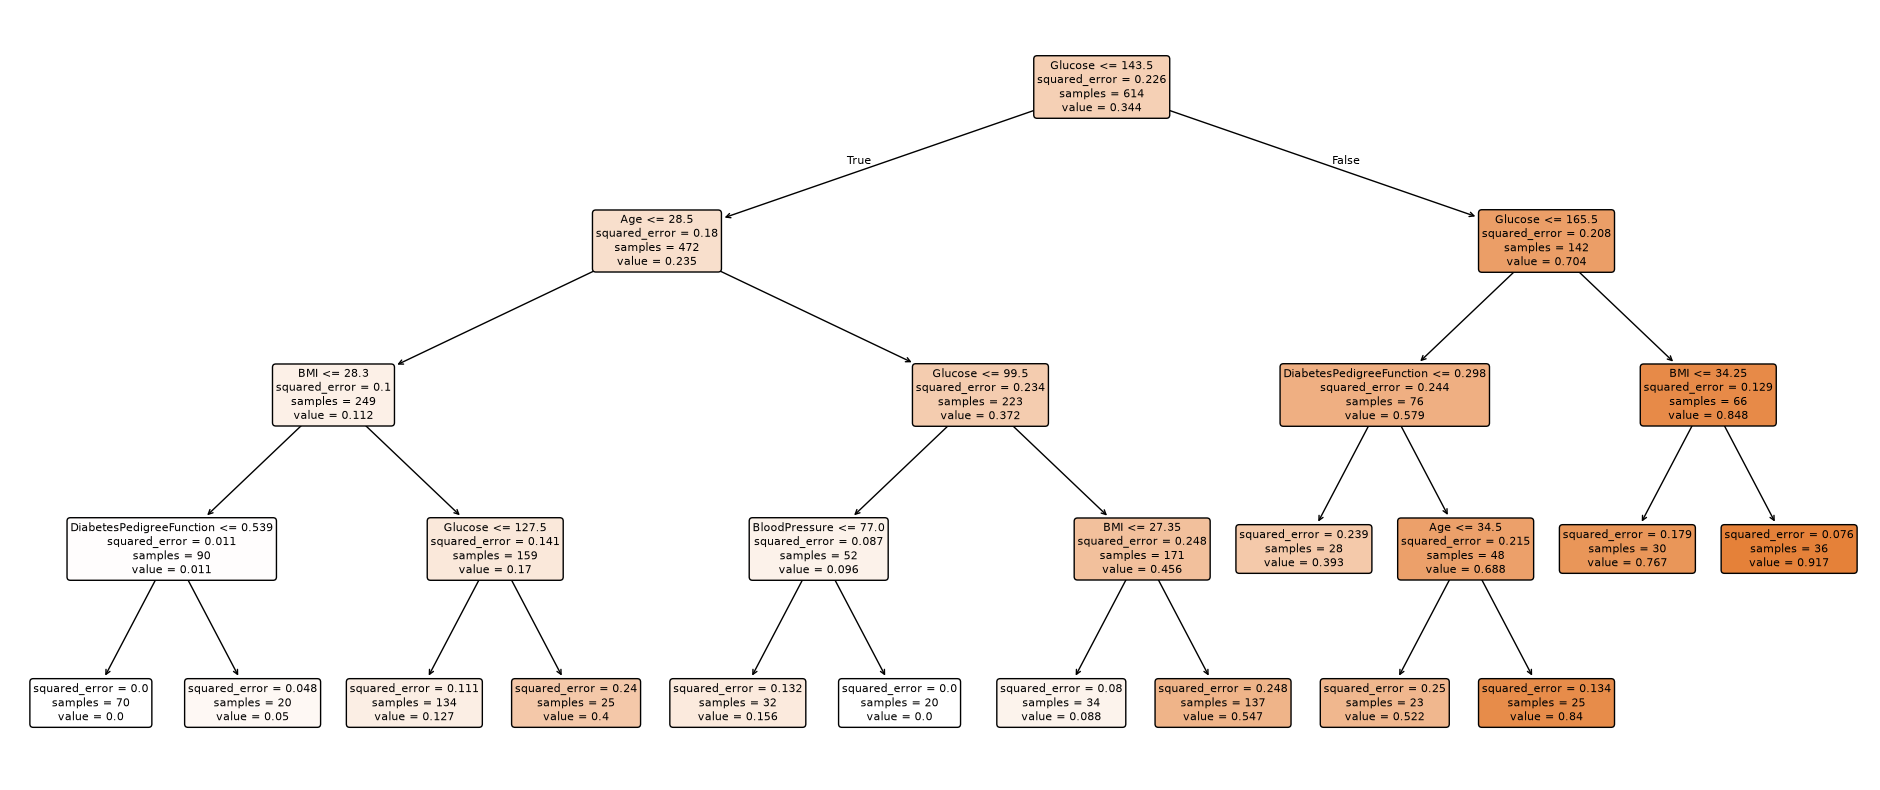

In [10]:
plt.figure(figsize=(24, 10))
plot_tree(reg, feature_names=list(features.columns), filled=True, rounded=True, fontsize=8)
plt.show()

In [11]:
# picture is hard to read so also as text, just top levels
print(tree.export_text(reg, feature_names=list(features.columns), max_depth=2))

|--- Glucose <= 143.50
|   |--- Age <= 28.50
|   |   |--- BMI <= 28.30
|   |   |   |--- truncated branch of depth 2
|   |   |--- BMI >  28.30
|   |   |   |--- truncated branch of depth 2
|   |--- Age >  28.50
|   |   |--- Glucose <= 99.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- Glucose >  99.50
|   |   |   |--- truncated branch of depth 2
|--- Glucose >  143.50
|   |--- Glucose <= 165.50
|   |   |--- DiabetesPedigreeFunction <= 0.30
|   |   |   |--- value: [0.39]
|   |   |--- DiabetesPedigreeFunction >  0.30
|   |   |   |--- truncated branch of depth 2
|   |--- Glucose >  165.50
|   |   |--- BMI <= 34.25
|   |   |   |--- value: [0.77]
|   |   |--- BMI >  34.25
|   |   |   |--- value: [0.92]



# FINAL THOUGHTS
Answer the following questions:
- What is the possible benefit of using a regressor instead of a classifier?
- What drawbacks can you imagine when using a regressor to complete a non-binary classification?
- Which metric do you need to optimize the model for? Accuracy, Precision, Recall, F1? Why?

Benefit of a regressor: it gives a number between 0 and 1 (basically the share of sick people in that leaf), so it works like a probability. I can pick my own threshold instead of always 0.5, sort patients by risk, and use it for AUC directly.

Drawbacks for non binary: if classes are like 0, 1, 2 the regressor treats them as numbers with order, so it thinks 2 is "more" than 1. If a leaf has half 0 and half 2 it predicts 1, which is a totally different class. Classes usually dont have any order so this makes no sense, and rounding the output wont fix it.

Metric: I would optimize recall, because missing a person who has diabetes is worse than a false alarm, they would just do one more test. But not recall alone, because predicting everyone as sick gives recall 1, so I also look at F1. My model got recall around 0.65 so it still misses about a third of sick people, not great